# The condition number of a linear system

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Appendix A, Section "Condition Number of a Linear System".

Every numerical method ends with a linear system $\mathbf{K}\mathbf{u} = \mathbf{f}$. The data are never exact:
at the very least they are rounded to the 16 significant digits of double precision. The **condition number**
$$\kappa(\mathbf{K}) = \max_{\mathbf{f},\,\delta\mathbf{f}} \frac{\|\delta\mathbf{u}\|/\|\mathbf{u}\|}{\|\delta\mathbf{f}\|/\|\mathbf{f}\|}$$
is the largest factor by which a relative error in the data can be amplified in the solution. For a symmetric
positive definite matrix it is the ratio of the extreme eigenvalues, $\kappa = \lambda_{\max}/\lambda_{\min}$.

**How to use it.** Run all the cells (*Runtime → Run all* in Colab), then change the parameters and run again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
n    = 20      # size of the matrices
p    = 10      # the second matrix has eigenvalues lambda**p (the first has lambda = 0.1, 0.2, ..., 2)
seed = 0       # random seed: change it to draw other eigenvectors and loads
# ---------------------------------------------------------------------------
rng = np.random.default_rng(seed)

## 1. Two matrices with the same eigenvectors

We build two symmetric positive definite matrices $\mathbf{K}_1 = \mathbf{Q}\,\boldsymbol{\Lambda}\,\mathbf{Q}^{\mathsf T}$
and $\mathbf{K}_2 = \mathbf{Q}\,\boldsymbol{\Lambda}^p\,\mathbf{Q}^{\mathsf T}$, with the same random orthonormal
eigenvectors (the columns of $\mathbf{Q}$) and eigenvalues $\lambda_i = 0.1, 0.2, \dots$ and $\lambda_i^p$.
The condition number is a property of the spectrum, not of the size of the entries: multiplying a matrix by
1000 changes every entry and leaves $\kappa$ unchanged.

K1: lambda_max/lambda_min = 2.000e+01,  np.linalg.cond = 2.000e+01
K2: lambda_max/lambda_min = 1.024e+13,  np.linalg.cond = 1.024e+13
1000*K1: np.linalg.cond = 2.000e+01


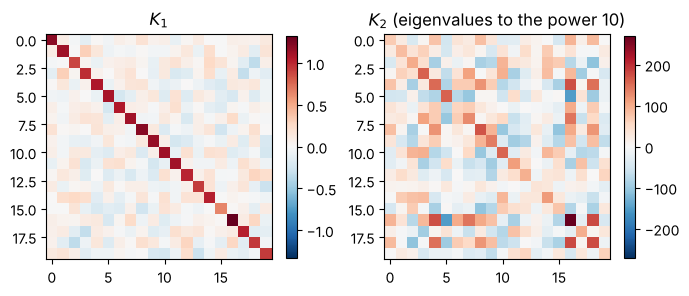

In [2]:
lam = np.arange(1, n + 1) / 10
Q, _ = np.linalg.qr(rng.standard_normal((n, n)))      # random orthonormal matrix
K1 = Q @ np.diag(lam) @ Q.T
K2 = Q @ np.diag(lam**p) @ Q.T

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, K, name in zip(axes, (K1, K2), ("$K_1$", f"$K_2$ (eigenvalues to the power {p})")):
    im = ax.imshow(K, cmap="RdBu_r", vmin=-abs(K).max(), vmax=abs(K).max())
    ax.set_title(name); fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

for K, name in ((K1, "K1"), (K2, "K2")):
    ev = np.linalg.eigvalsh(K)
    print(f"{name}: lambda_max/lambda_min = {ev[-1] / ev[0]:.3e},  np.linalg.cond = {np.linalg.cond(K):.3e}")
print(f"1000*K1: np.linalg.cond = {np.linalg.cond(1000 * K1):.3e}")

## 2. Perturbing the loads

Solve with a load $\mathbf{f}$ and with a perturbed load $\mathbf{f}+\delta\mathbf{f}$, and measure the
amplification of the relative error. By linearity $\delta\mathbf{u} = \mathbf{K}^{-1}\delta\mathbf{f}$.

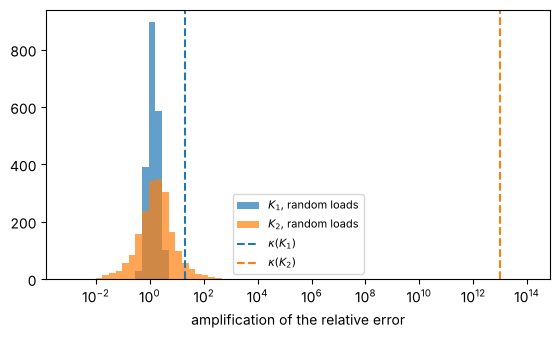

In [3]:
def amplification(K, f, df):
    u, du = np.linalg.solve(K, f), np.linalg.solve(K, df)
    return (np.linalg.norm(du) / np.linalg.norm(u)) / (np.linalg.norm(df) / np.linalg.norm(f))

amp1 = [amplification(K1, rng.random(n), rng.standard_normal(n)) for _ in range(2000)]
amp2 = [amplification(K2, rng.random(n), rng.standard_normal(n)) for _ in range(2000)]

fig, ax = plt.subplots(figsize=(6.5, 3.5))
bins = np.logspace(-3, 14, 70)
ax.hist(amp1, bins=bins, alpha=0.7, label="$K_1$, random loads")
ax.hist(amp2, bins=bins, alpha=0.7, label="$K_2$, random loads")
ax.axvline(np.linalg.cond(K1), color="C0", ls="--", label=r"$\kappa(K_1)$")
ax.axvline(np.linalg.cond(K2), color="C1", ls="--", label=r"$\kappa(K_2)$")
ax.set_xscale("log"); ax.set_xlabel("amplification of the relative error"); ax.legend(fontsize=8)
plt.show()

Surprise: with random loads the amplification is modest even for $\mathbf{K}_2$. A random load has components
along all the eigenvectors; its response, and that of a random perturbation, are both dominated by the most
compliant directions (smallest eigenvalues), and the ratio stays of order one.

$\kappa$ is a **worst case**. It is reached when the load acts along the stiffest direction (small response) and
the perturbation along the most compliant one (large response):

In [4]:
v_stiff, v_soft = Q[:, -1], Q[:, 0]                   # eigenvectors of lambda_max and lambda_min
for K, name in ((K1, "K1"), (K2, "K2")):
    print(f"{name}: worst-case amplification = {amplification(K, v_stiff, 1e-8 * v_soft):.3e}")

K1: worst-case amplification = 2.000e+01
K2: worst-case amplification = 1.024e+13


## 3. Round-off does find the worst case

We do not choose the errors of floating-point arithmetic: they hit every entry of $\mathbf{K}$ and $\mathbf{f}$,
in every direction. Choose a displacement $\mathbf{u}$, compute the load $\mathbf{f} = \mathbf{K}\mathbf{u}$
that produces it, solve back, and compare. The relative error grows like $\kappa\,\varepsilon$, with
$\varepsilon \approx 10^{-16}$ the machine precision: we lose about $\log_{10}\kappa$ significant digits.

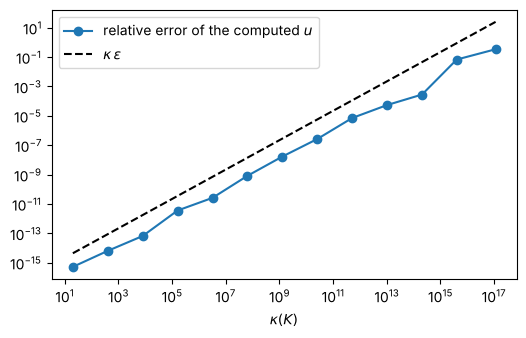

In [5]:
powers = np.arange(1, 14)
kappas, errors = [], []
for q in powers:
    K = Q @ np.diag(lam**q) @ Q.T
    u = rng.random(n)
    f = K @ u
    kappas.append(np.linalg.cond(K))
    errors.append(np.linalg.norm(np.linalg.solve(K, f) - u) / np.linalg.norm(u))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(kappas, errors, "o-", label="relative error of the computed $u$")
ax.loglog(kappas, np.array(kappas) * np.finfo(float).eps, "k--", label=r"$\kappa\,\varepsilon$")
ax.set_xlabel(r"$\kappa(K)$"); ax.legend()
plt.show()

## 4. Two matrices from the book

* The **stiffness matrix** of a bar fixed at one end and divided into $N$ equal linear finite elements is
  $\frac{k}{h}\,\mathrm{tridiag}(-1, 2, -1)$, with a 1 in the last diagonal entry (the free end). Its condition
  number grows like $N^2$: refining the mesh costs digits, but slowly.
* The **Gram matrix of the monomials** $1, x, \dots, x^{N-1}$ in $L^2(0,1)$, the Hilbert matrix of
  Example "Monomials Are Nearly Parallel" in Chapter 4: its condition number grows exponentially.

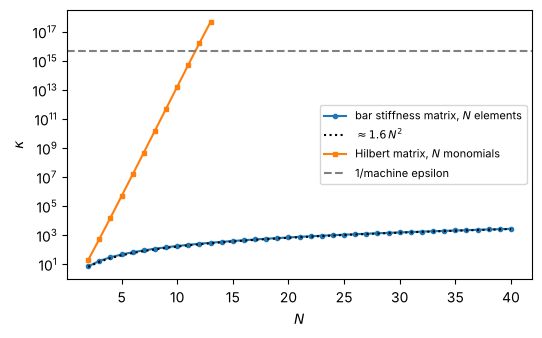

In [6]:
Ns = np.arange(2, 41)
k_bar, k_hilbert = [], []
for N in Ns:
    K = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    K[-1, -1] = 1
    k_bar.append(np.linalg.cond(K))
    i = np.arange(N)
    k_hilbert.append(np.linalg.cond(1.0 / (i[:, None] + i[None, :] + 1)) if N <= 13 else np.nan)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(Ns, k_bar, "o-", ms=3, label="bar stiffness matrix, $N$ elements")
ax.semilogy(Ns, 1.6 * Ns**2.0, "k:", label=r"$\approx 1.6\,N^2$")
ax.semilogy(Ns, k_hilbert, "s-", ms=3, label="Hilbert matrix, $N$ monomials")
ax.axhline(1 / np.finfo(float).eps, color="gray", ls="--", label="1/machine epsilon")
ax.set_xlabel("$N$"); ax.set_ylabel(r"$\kappa$"); ax.legend(fontsize=8)
plt.show()

## Things to try
1. Change `p`: how many digits does the solve of Section 3 lose for `p = 5`? Does it match $\log_{10}\kappa$?
2. In Section 2, use loads with a large component along `v_stiff` (e.g. `f = v_stiff + 0.01*rng.random(n)`).
   How does the histogram change?
3. Two independent springs, a stiff one $k_s$ and a soft one $k_c$, each restraining its own degree of freedom,
   have the stiffness matrix
   $\mathrm{diag}(k_s, k_c)$. Check that $\kappa = k_s/k_c$ and find the load and the perturbation that reach it.
4. In Section 4, make the bar stiffness vary along the axis (multiply the element stiffnesses by a factor 100 in
   half of the bar). How does $\kappa$ change?